# lab4 — Hand Extractor: จับมือให้แม่น · นิ่ง · เร็ว (real-time) ก่อนส่งต่อ Sign Model

**เป้าหมาย** (โฟกัสที่ *มือล้วนๆ* และ **real-time ในเบราว์เซอร์**): ① มือจับไม่ค่อยโดน ② landmark แม่นพอสำหรับ Uni-Sign ③ ตามมือนิ่งตอนเปลี่ยนท่า/มุม/เบลอ/เร็ว — และ **ทำทั้งหมดนี้โดยไม่ช้าลงจนเกินงบ real-time**

ไม่รื้อระบบเดิม: ทดลองเป็น A/B ตาม research ที่ให้มา แล้วเพิ่มวิธีที่ผมเสนอเอง + **YOLO11 (ตัวปัจจุบันของ Ultralytics) เทรนจาก weight เริ่มต้น `yolo11n-pose` บน hand-keypoints dataset**

| | วิธี | แนวคิด |
|---|---|---|
| **A** | Holistic (production ตอนนี้) | baseline |
| **B** | Holistic → Pose+Face, **Hand Landmarker → มือ** | แยกมือเป็นอิสระ (ตามข้อเสนอ Experiment B) |
| **C** | Holistic + **ROI Recovery** | Holistic ยังเป็นหลัก; ถ้ามือหาย → crop **ขยาย** รอบข้อมือ (จาก pose / ตำแหน่งมือเฟรมก่อน) แล้วให้ Hand Landmarker หาใหม่ — ตรงกับข้อสรุปข้อ 5 ของคุณ (recovery layer) |
| **D** | Fusion: Holistic + Hand Landmarker + ROI | เลือกผู้สมัครต่อข้างด้วย pose-wrist + ความต่อเนื่อง, ซ่อม identity swap |
| **E** | Hand Landmarker (tracking) + ROI Recovery | ถูกกว่า D: ไม่ใช้มือจาก Holistic |
| **F** | Holistic + **YOLO-ROI recovery** | เหมือน C แต่ ROI มาจาก **กล่องมือของ YOLO11** (เรียกเฉพาะเฟรมที่มือหาย) |
| **G** | **YOLO box → Hand Landmarker บน crop** | YOLO หามือทุกเฟรม แล้ว MediaPipe วาด 21 จุดบน crop ขยาย (ไม่ใช้ palm detector เต็มเฟรม) |
| **+P** | Post-process (ใช้ได้กับทุกวิธี) | อุดช่องว่างสั้น (paper KAIST) + **One-Euro filter** (นิ่งโดยไม่หน่วง) |

> วัด 5 อย่าง: **Missing-Frame Rate · Landmark PCK · Jitter · Recognition (WER ของ Sign Model จริง) · ms/เฟรม** ในเงื่อนไขที่เลียนปัญหา real-time บนเว็บ (มือเล็ก/ไกล · มืด · เฟรมหล่น fps÷3)

## 1. Research — เอามาต่อยอดอะไรได้บ้าง

### 1.1 สองงานที่ให้มา
| งาน | ทำอะไร | ได้อะไรที่เอามาใช้ |
|---|---|---|
| **Roh+ 2024 (KAIST, LREC-COLING SLTAT)** Keypoint Reconstruction & Anchors | MediaPipe Holistic พลาดมือ **>50%** ของเฟรมใน WLASL (detect 46.6%; AUTSL 78.8%) → ① normalize ด้วย **anchor คอ** (origin = คอ, หน่วย = ความยาวคอ→หัว) ② มือ normalize **แยก** โดยใช้ anchor ที่ฝ่ามือ (ไม่ normalize ขนาด เพราะขนาด = ระยะจากลำตัว) ③ **อุดมือที่หายด้วย interpolation** จากเฟรมก่อน-หลัง ④ ยืดความยาว sequence ให้คงที่ → WLASL-100 **+6.05%**, 83.26% | ③ = `fill_gaps` (ใช้แล้วใน `schema.fill_hand_gaps` ≤0.2 s); ① anchor = `norm_body`; งานนี้ยืนยันว่า **มือที่หาย คือคอขวดของ accuracy** |
| **Remiro+ 2023 (UPM, ECSA-10)** Localization & Zoom normalization | landmark ของ MediaPipe Hands ยังแปรผันตาม **ตำแหน่ง/ขนาดมือ** → `Norm_Loc` (ข้อมือ = origin) + `Norm_Zoom` (ปรับให้พอดีกล่อง 1×1) → ภายใต้ความแปรปรวนสูง **43.9% → 89.0%** | `norm_wrist`, `norm_zoom` — และหลักการเดียวกันใช้ที่ระดับ *ภาพ*: **crop+ขยายมือให้ขนาดคงที่ก่อนเข้า landmark model** = ROI Recovery ของเรา |

### 1.2 สิ่งที่ผมเพิ่มจากการค้นคว้า
| แนวทาง | สถานะ | ความเห็น |
|---|---|---|
| **Two-stage ROI/zoom (palm detector → landmark)** | ทำและวัดในแล็บนี้ (C, D, E) | palm detector ของ MediaPipe ทำงานที่ภาพ ~192×192 ทั้งเฟรม → มือเล็ก/ไกลหาย; crop ขยายแก้ที่ต้นเหตุ |
| **Temporal ROI tracking** (ใช้กล่องมือเฟรมก่อน + ความเร็ว) | ทำ (`bbox_roi`) | Holistic ตามมือด้วย pose-guided ROI เท่านั้น; ถ้า pose เพี้ยนตอนมือเร็ว มือหลุด |
| **Pose-wrist gating + identity fix** | ทำ (`assign_sides`, `plausible`) | กันมือคนอื่น/พื้นหลัง และมือซ้าย-ขวาสลับ |
| **One-Euro filter** | ทำ | ลด jitter โดยหน่วงน้อยกว่า EMA/Kalman ค่าคงที่ — มาตรฐานของงาน hand/face tracking |
| **YOLO11 เป็นตัวหา proposal ก่อน MediaPipe** | **ทดสอบแล้ว (F, G — หัวข้อ 3.5)** | YOLO11n-pose เทรนต่อจาก weight ทางการ `yolo11n-pose.pt` บน Ultralytics hand-keypoints (CPU, เวลาจำกัด) แล้ว export ONNX; ใช้เฉพาะ *กล่อง* เป็น ROI ให้ MediaPipe |
| **Whole-body RTMW / ViTPose-hand** | v10 เทสแล้ว **แพ้** MediaPipe บนข้อมูลเรา | ช้ากว่าและไม่ตรงกับ browser |
| **HaMeR / WiLoR (3D hand mesh)** | ไม่เหมาะ real-time | GPU หนัก, ใช้เป็น offline pseudo-GT ได้ในอนาคต |
| **Hand keypoint reconstruction model** (`modules/masked_hand.py` มีอยู่) | เป็นฝั่ง training | ต่อยอดได้เมื่ออัตรา missing ลดแล้ว |

### 1.3 "Normalize" — ระบบหลักทำอะไรไว้แล้ว?
อ่านจาก `modules/parts.py::prepare_parts` (= `load_part_kp` ของ Uni-Sign ทุกประการ):

| ขั้น | ตอนนี้ | หมายเหตุ |
|---|---|---|
| ตำแหน่งมือ | ✅ ข้อมือ = origin (เหมือน `Norm_Loc`) | |
| สเกลมือ | ⚠️ หารด้วย **สเกลลำตัว** (bbox ของ body) ไม่ใช่ขนาดมือ | ตรงกับ paper KAIST (ขนาดมือ = ข้อมูลระยะ) แต่ถ้ามือถูกจับ "เล็ก/ไกลเกินจริง" จะเพี้ยน |
| การหมุนมือ | ❌ ไม่มี | roll ของข้อมือเปลี่ยน descriptor |
| ภาพ (exposure) | ✅ `ExposureNorm` (แต่ pitty พบว่าบน data_test ทำให้ miss เพิ่ม → ปิดใน extract) | |
| **ภาพ (zoom มือ)** | ❌ **ไม่มี** ← ช่องว่างหลัก | ROI Recovery คือ zoom normalization ระดับภาพ |

**ข้อสรุป:** Sign Model ถูกเทรนมาด้วย normalization เดิม → *อย่าเปลี่ยน normalization ที่ป้อนเข้าโมเดลโดยไม่เทรนใหม่*. สิ่งที่แก้ได้ทันที = **คุณภาพ landmark** (หา/อุด/ทำให้นิ่ง) + normalize ระดับ**ภาพ** (zoom). ส่วน `norm_zoom/norm_rot` เหมาะกับโมดูล hand-shape / fingerspelling (หัวข้อ 4 วัดว่าดีขึ้นเท่าไร).

In [1]:
import os, sys, time, glob, pickle, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
assert (ROOT / "modules").is_dir(), "เปิด notebook จาก root ของ repo"
sys.path.insert(0, str(ROOT)); os.environ["PYTHONPATH"] = str(ROOT) + os.pathsep + os.environ.get("PYTHONPATH", "")
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt

QUICK = False          # True = ชุดย่อย (~5 นาที) · False = ชุดเต็ม (~20 นาที)
N_JOBS = 5             # process คู่ขนานของ benchmark (วัดความเร็วใช้ cell แยกที่รันทีละ process)
RUN_CAMERA = False     # True = เปิดกล้องใน cell ท้ายสุด
SOURCE = 0             # กล้อง 0 หรือ path วิดีโอ
MODEL_DIR = ROOT / "models" / "model-v10"
YOLO_DIR = ROOT / "PoC" / "yolo" / "weights"      # hand_yolo11n.onnx (ผลเทรนในแล็บนี้) · ข้อมูล = PoC/yolo/data
TRAIN_YOLO = False     # True = เทรน YOLO ใหม่ (ต้องมี ultralytics; CPU ~45 นาที) — ถ้า False ใช้ไฟล์ .onnx ที่มีอยู่
DATA = ROOT / "data_test"

In [2]:
"""hand extractor lab — library (embedded in lab4-handExtractor.ipynb)."""
from __future__ import annotations

import math
import os
import time
from pathlib import Path

import cv2
import numpy as np

HAND_MODEL_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
HAND_MODEL = Path(os.environ.get("MP_HAND_MODEL", Path.home() / ".cache" / "mediapipe_tasks" / "hand_landmarker.task"))

# pose landmarks: (wrist, elbow, pinky, index, thumb) of each side;  MediaPipe naming = the person's own side (same as Holistic lh / rh)
SIDE = {"L": dict(wrist=15, elbow=13, pinky=17, index=19, thumb=21, shoulder=11), "R": dict(wrist=16, elbow=14, pinky=18, index=20, thumb=22, shoulder=12)}
HIP = (23, 24)


def ensure_hand_model(path=HAND_MODEL):
    path = Path(path)
    if not path.exists():
        import urllib.request
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(HAND_MODEL_URL, path)
    return path


# ------------------------------------------------------------------------------------------------------------ models
class HandNet:
    """MediaPipe Hand Landmarker (palm detector + 21-point landmark model).  video=True → tracking across frames (the landmark model
    re-uses the previous hand box, the palm detector only runs when a hand is lost);  video=False → every call detects from scratch
    (used on ROI crops, which are not a continuous video)."""

    def __init__(self, video=True, num_hands=2, det=0.5, pres=0.5, trk=0.5, model=None):
        from mediapipe.tasks.python import BaseOptions, vision
        mode = vision.RunningMode.VIDEO if video else vision.RunningMode.IMAGE
        self.video = video
        self.lm = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
            base_options=BaseOptions(model_asset_path=str(ensure_hand_model(model or HAND_MODEL))), running_mode=mode, num_hands=num_hands,
            min_hand_detection_confidence=det, min_hand_presence_confidence=pres, min_tracking_confidence=trk))

    def close(self):
        self.lm.close()

    def __call__(self, rgb, t_ms=0):
        """→ [{lm [21,3] (x/W, y/H, z), score, label}]"""
        import mediapipe as mp
        img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
        r = self.lm.detect_for_video(img, int(t_ms)) if self.video else self.lm.detect(img)
        out = []
        for lm, hd in zip(r.hand_landmarks, r.handedness):
            out.append(dict(lm=np.array([(p.x, p.y, p.z) for p in lm], np.float32), score=float(hd[0].score), label=hd[0].category_name[0]))
        return out


# ------------------------------------------------------------------------------------------------------------ geometry
def px(lm, hw):
    """normalised (x/W, y/H, z) → pixels"""
    H, W = hw
    return lm[..., :2] * np.array([W, H], np.float32)


def hand_size(lm2):
    """bounding-box side of a 21-point hand (any unit)"""
    return float(np.max(lm2.max(0) - lm2.min(0)))


def pose_hand_roi(pose, side, hw):
    """Where the pose model thinks this hand is: (centre px, square side px, ok).  Uses wrist / pinky / index / thumb points and the
    forearm length as the size prior (a hand is ~0.4 × forearm long, the ROI must hold the whole hand with margin)."""
    H, W = hw
    ix = SIDE[side]
    if pose[ix["wrist"], 3] < 0.3:
        return None
    P = pose[:, :2] * np.array([W, H], np.float32)
    w, e = P[ix["wrist"]], P[ix["elbow"]]
    tips = P[[ix["pinky"], ix["index"], ix["thumb"]]].mean(0)
    c = 0.5 * (w + tips) if pose[[ix["pinky"], ix["index"], ix["thumb"]], 3].mean() > 0.3 else w
    fore = np.linalg.norm(w - e) if pose[ix["elbow"], 3] > 0.3 else 0.0
    sh = np.linalg.norm(P[11] - P[12]) if pose[11, 3] > 0.3 and pose[12, 3] > 0.3 else 0.0
    s = max(1.15 * fore, 0.55 * sh, 3.2 * np.linalg.norm(tips - w), 48.0)
    return c, float(min(s, 0.9 * max(H, W))), True


def crop_square(rgb, c, s, out=256, ang=0.0):
    """Rotated square crop of side s centred on c (px), resized to out×out.  Returns (crop, M) with M the 2×3 affine crop→image."""
    a = math.radians(ang)
    k = s / out
    R = np.array([[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]], np.float32) * k
    t = np.asarray(c, np.float32) - R @ np.array([out / 2, out / 2], np.float32)
    M = np.concatenate([R, t[:, None]], 1)
    crop = cv2.warpAffine(rgb, M, (out, out), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(114, 114, 114))
    return crop, M


def back_project(lm_crop, M, out, hw):
    """landmarks normalised to the crop → normalised to the full frame"""
    H, W = hw
    p = lm_crop[:, :2] * out
    q = p @ M[:, :2].T + M[:, 2]
    res = np.empty_like(lm_crop)
    res[:, 0], res[:, 1] = q[:, 0] / W, q[:, 1] / H
    k = float(np.linalg.norm(M[:, 0]))                    # crop px → image px
    res[:, 2] = lm_crop[:, 2] * out * k / W
    return res


def bbox_roi(lm, hw, scale=2.0, vel=None):
    """ROI from the previous hand landmarks (temporal tracking): centre of the box (+ velocity), side = scale × box"""
    H, W = hw
    p = px(lm, hw)
    c = (p.max(0) + p.min(0)) / 2
    if vel is not None:
        c = c + vel
    return c, float(max(hand_size(p) * scale, 40.0))


def forearm_angle(pose, side, hw):
    """in-plane rotation (deg) that makes the forearm point up (palm detector works best on upright hands)"""
    ix = SIDE[side]
    if pose[ix["wrist"], 3] < 0.3 or pose[ix["elbow"], 3] < 0.3:
        return 0.0
    H, W = hw
    d = (pose[ix["wrist"], :2] - pose[ix["elbow"], :2]) * np.array([W, H], np.float32)
    # angle of the forearm direction measured from "up" (0,-1); rotate the crop by it
    return float(math.degrees(math.atan2(d[0], -d[1])))


# ------------------------------------------------------------------------------------------------------------ side assignment
def assign_sides(hands, pose, hw):
    """Hand Landmarker returns hands without knowing who is who.  Give each hand to the pose wrist it is nearest to (the model's own
    handedness label is only the tie-break when the pose wrist is hidden)."""
    out = {"L": None, "R": None}
    if not hands:
        return out
    H, W = hw
    wr = {s: (pose[SIDE[s]["wrist"], :2] * np.array([W, H], np.float32), pose[SIDE[s]["wrist"], 3] > 0.3) for s in "LR"}
    cand = []
    for h in hands:
        w = px(h["lm"], hw)[0]
        for s in "LR":
            d = np.linalg.norm(w - wr[s][0]) if wr[s][1] else 1e4
            # distance in units of the hand's own size; label mismatch adds a small penalty
            cand.append((d / max(hand_size(px(h["lm"], hw)), 1.0) + (0.0 if h["label"] == s else 0.35), s, h))
    cand.sort(key=lambda x: x[0])
    used = set()
    for cost, s, h in cand:
        if out[s] is None and id(h) not in used and cost < 6.0:
            out[s] = h; used.add(id(h))
    return out


def plausible(lm, pose, side, hw, tol=1.4):
    """a candidate hand must sit on the pose wrist (≤ tol × forearm) — filters background hands and identity swaps"""
    H, W = hw
    ix = SIDE[side]
    if pose[ix["wrist"], 3] < 0.3:
        return True
    p = px(lm, hw)
    w = pose[ix["wrist"], :2] * np.array([W, H], np.float32)
    fore = np.linalg.norm((pose[ix["wrist"], :2] - pose[ix["elbow"], :2]) * np.array([W, H], np.float32)) if pose[ix["elbow"], 3] > 0.3 else 0.15 * max(H, W)
    return bool(np.linalg.norm(p[0] - w) <= tol * max(fore, 30.0))


# ------------------------------------------------------------------------------------------------------------ extractors
def _empty():
    return np.zeros((21, 3), np.float32)


class ExtractorBase:
    name = "?"

    def __init__(self):
        self.ms = []
        self.src = {"L": [], "R": []}                # which source produced each frame's hand (diagnostics)

    def close(self):
        pass

    def frame(self, rgb, t_ms):
        t0 = time.perf_counter()
        out = self._frame(rgb, t_ms)
        self.ms.append((time.perf_counter() - t0) * 1000)
        return out


class A_Holistic(ExtractorBase):
    """Experiment A — baseline: MediaPipe Holistic as it is in production (modules/mediapipe_pose.py)."""
    name = "A Holistic"

    def __init__(self, holistic=None):
        super().__init__()
        from modules.mediapipe_pose import Holistic
        self.h = holistic or Holistic()

    def close(self):
        self.h.close()

    def _frame(self, rgb, t_ms):
        pose, lh, rh, face, bs = self.h.frame(rgb, t_ms)
        for s, a in (("L", lh), ("R", rh)):
            self.src[s].append("holistic" if a.any() else "-")
        return pose, lh, rh, face, bs


class B_IndependentHand(A_Holistic):
    """Experiment B — Holistic gives face + pose, the Hand Landmarker (full frame, tracking) gives both hands."""
    name = "B Independent hand"

    def __init__(self, **kw):
        super().__init__()
        self.net = HandNet(video=True, **kw)

    def close(self):
        super().close(); self.net.close()

    def _frame(self, rgb, t_ms):
        pose, lh0, rh0, face, bs = self.h.frame(rgb, t_ms)
        hw = rgb.shape[:2]
        sides = assign_sides(self.net(rgb, t_ms), pose, hw)
        out = {}
        for s in "LR":
            h = sides[s]
            out[s] = h["lm"] if h is not None else _empty()
            self.src[s].append("hand" if h is not None else "-")
        return pose, out["L"], out["R"], face, bs


class C_Recovery(A_Holistic):
    """Holistic stays the main source; when it loses a hand, a Hand Landmarker is run on a ZOOMED ROI (previous hand box, else the
    pose wrist) — a recovery layer that does not touch the working path."""
    name = "C Holistic + ROI recovery"

    def __init__(self, out=256, rotate=True, **kw):
        super().__init__()
        self.net = HandNet(video=False, num_hands=2, det=0.4, pres=0.4)
        self.out, self.rotate = out, rotate
        self.prev = {"L": None, "R": None}           # (landmarks, frame index)
        self.cool = {"L": 0, "R": 0}                 # frames to wait after a failed recovery (a hand that is not there costs nothing)
        self.cool_fail = {"L": 0, "R": 0}
        self.vel = {"L": np.zeros(2, np.float32), "R": np.zeros(2, np.float32)}
        self.i = 0

    def close(self):
        super().close(); self.net.close()

    @staticmethod
    def raised(pose, side, margin=0.05):
        hip = pose[HIP[0 if side == "L" else 1]]
        return bool(hip[3] < 0.3 or pose[SIDE[side]["wrist"], 1] < hip[1] + margin)

    def rois(self, rgb, pose, side, hw):
        return []

    def rescue(self, rgb, pose, side, other):
        hw = rgb.shape[:2]
        if self.cool[side] > 0:
            self.cool[side] -= 1
            return None, "-"
        rois = []
        if self.prev[side] is not None and self.i - self.prev[side][1] <= 12:                       # 1) temporal ROI (the hand was just here)
            c, s = bbox_roi(self.prev[side][0], hw, 2.2, self.vel[side] * (self.i - self.prev[side][1]))
            rois.append(("track", c, s, 0.0))
        pr = pose_hand_roi(pose, side, hw)
        if pr is not None and not self.raised(pose, side):                                          # hand hanging down: nothing to sign, save the compute
            pr = None
        if pr is not None:                                                                         # 2) pose-guided ROI
            ang = forearm_angle(pose, side, hw) if self.rotate else 0.0
            rois.append(("pose", pr[0], pr[1], ang))
            if self.rotate and self.cool_fail[side] % 3 == 2:                                       # wider, upright retry now and then
                rois.append(("pose", pr[0], pr[1] * 1.5, 0.0))
        rois = self.rois(rgb, pose, side, hw) + rois
        for kind, c, s, ang in rois:
            crop, M = crop_square(rgb, c, s, self.out, ang)
            for h in self.net(crop):
                if h["score"] < 0.6:
                    continue
                lm = back_project(h["lm"], M, self.out, hw)
                if not plausible(lm, pose, side, hw):
                    continue
                if other is not None and np.linalg.norm(px(lm, hw)[0] - px(other, hw)[0]) < 0.25 * hand_size(px(other, hw)):
                    continue                                                                       # same hand as the other side
                self.cool_fail[side] = 0
                return lm, kind
        self.cool_fail[side] += 1
        self.cool[side] = 2 if rois else 0                                                          # retry every 3rd frame
        return None, "-"

    def _frame(self, rgb, t_ms):
        pose, lh, rh, face, bs = self.h.frame(rgb, t_ms)
        res = {"L": lh, "R": rh}
        for s in "LR":
            if res[s].any():
                self.src[s].append("holistic")
            else:
                other = res["R" if s == "L" else "L"]
                lm, kind = self.rescue(rgb, pose, s, other if other.any() else None)
                res[s] = lm if lm is not None else _empty()
                self.src[s].append(kind)
        for s in "LR":
            if res[s].any():
                if self.prev[s] is not None:
                    d = px(res[s], rgb.shape[:2])[0] - px(self.prev[s][0], rgb.shape[:2])[0]
                    self.vel[s] = 0.6 * self.vel[s] + 0.4 * d / max(self.i - self.prev[s][1], 1)
                self.prev[s] = (res[s].copy(), self.i)
        self.i += 1
        return pose, res["L"], res["R"], face, bs


class D_Fusion(C_Recovery):
    """Recommended: three sources, one decision.  Holistic hands + a full-frame Hand Landmarker (tracking) + ROI recovery.  Per side the
    candidate that agrees with the pose wrist AND the previous frame wins; identity swaps are repaired; the ROI recovery only runs for a
    side that is still empty."""
    name = "D Fusion (Holistic + Hand + ROI)"

    def __init__(self, **kw):
        super().__init__(**kw)
        self.vid = HandNet(video=True)

    def close(self):
        super().close(); self.vid.close()

    def _score(self, lm, pose, side, hw, side_prev):
        if not plausible(lm, pose, side, hw):
            return None
        c = 0.0
        if side_prev is not None:
            p, p0 = px(lm, hw), px(side_prev[0], hw)
            c += np.linalg.norm(p[0] - p0[0]) / max(hand_size(p0), 1.0)
        ix = SIDE[side]
        if pose[ix["wrist"], 3] > 0.3:
            c += 0.5 * np.linalg.norm(px(lm, hw)[0] - pose[ix["wrist"], :2] * np.array([hw[1], hw[0]])) / max(hand_size(px(lm, hw)), 1.0)
        return c

    def _frame(self, rgb, t_ms):
        pose, lh, rh, face, bs = self.h.frame(rgb, t_ms)
        hw = rgb.shape[:2]
        hl = assign_sides(self.vid(rgb, t_ms), pose, hw)
        res, srcs = {}, {}
        for s, hol in (("L", lh), ("R", rh)):
            cands = []
            if hol.any():
                cands.append(("holistic", hol))
            if hl[s] is not None:
                cands.append(("hand", hl[s]["lm"]))
            best, bs_ = None, 1e9
            for name, lm in cands:
                sc = self._score(lm, pose, s, hw, self.prev[s] if self.prev[s] is not None and self.i - self.prev[s][1] <= 12 else None)
                if sc is not None and sc < bs_:
                    best, bs_ = (name, lm), sc
            res[s], srcs[s] = (best[1], best[0]) if best else (None, "-")
        for s in "LR":
            if res[s] is None:
                other = res["R" if s == "L" else "L"]
                lm, kind = self.rescue(rgb, pose, s, other)
                res[s], srcs[s] = (lm, kind) if lm is not None else (None, "-")
        for s in "LR":
            self.src[s].append(srcs[s])
            if res[s] is not None:
                if self.prev[s] is not None:
                    d = px(res[s], hw)[0] - px(self.prev[s][0], hw)[0]
                    self.vel[s] = 0.6 * self.vel[s] + 0.4 * d / max(self.i - self.prev[s][1], 1)
                self.prev[s] = (res[s].copy(), self.i)
            else:
                res[s] = _empty()
        self.i += 1
        return pose, res["L"], res["R"], face, bs


class E_FastRecovery(D_Fusion):
    """Real-time variant: the Hand Landmarker (tracking, full frame) is the main hand source; ROI recovery only for a side that is still empty
    AND raised.  Holistic hands are ignored (they are computed anyway inside Holistic)."""
    name = "E Hand tracker + ROI recovery"

    def _frame(self, rgb, t_ms):
        pose, lh, rh, face, bs = self.h.frame(rgb, t_ms)
        hw = rgb.shape[:2]
        hl = assign_sides(self.vid(rgb, t_ms), pose, hw)
        res, srcs = {}, {}
        for s in "LR":
            if hl[s] is not None and plausible(hl[s]["lm"], pose, s, hw):
                res[s], srcs[s] = hl[s]["lm"], "hand"
            else:
                res[s], srcs[s] = None, "-"
        for s in "LR":
            if res[s] is None:
                lm, kind = self.rescue(rgb, pose, s, res["R" if s == "L" else "L"])
                res[s], srcs[s] = (lm, kind) if lm is not None else (None, "-")
        for s in "LR":
            self.src[s].append(srcs[s])
            if res[s] is not None:
                if self.prev[s] is not None:
                    d = px(res[s], hw)[0] - px(self.prev[s][0], hw)[0]
                    self.vel[s] = 0.6 * self.vel[s] + 0.4 * d / max(self.i - self.prev[s][1], 1)
                self.prev[s] = (res[s].copy(), self.i)
            else:
                res[s] = _empty()
        self.i += 1
        return pose, res["L"], res["R"], face, bs


# ------------------------------------------------------------------------------------------------------------ YOLO proposals
class YoloHand:
    """YOLO11-pose fine-tuned on the Ultralytics hand-keypoints set, exported to ONNX (runs in onnxruntime here, onnxruntime-web in the
    browser).  Only the BOX is used: it proposes where a hand is; MediaPipe's landmark model still draws the 21 points on a zoomed crop."""

    def __init__(self, onnx, imgsz=320, conf=0.25, providers=None):
        import onnxruntime as ort
        self.s = ort.InferenceSession(str(onnx), providers=providers or ["CPUExecutionProvider"])
        self.inp = self.s.get_inputs()[0].name
        self.imgsz, self.conf = imgsz, conf

    def __call__(self, rgb):
        H, W = rgb.shape[:2]
        r = self.imgsz / max(H, W)
        nh, nw = int(round(H * r)), int(round(W * r))
        im = np.full((self.imgsz, self.imgsz, 3), 114, np.uint8)
        im[:nh, :nw] = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
        x = (im.astype(np.float32) / 255.0).transpose(2, 0, 1)[None]
        o = self.s.run(None, {self.inp: x})[0][0].T                     # [N, 5+63]
        o = o[o[:, 4] > self.conf]
        if not len(o):
            return []
        b = o[:, :4] / r
        boxes = np.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 2], b[:, 3]], 1)
        keep = cv2.dnn.NMSBoxes(boxes.tolist(), o[:, 4].tolist(), self.conf, 0.5)
        return [(float(b[i, 0]), float(b[i, 1]), float(b[i, 2]), float(b[i, 3]), float(o[i, 4])) for i in np.array(keep).reshape(-1)]


class F_YoloRecovery(C_Recovery):
    """C, but the recovery ROI comes from a YOLO hand box (full frame, run lazily: only on frames where a hand is missing and raised)
    before falling back to the pose guess."""
    name = "F Holistic + YOLO-ROI recovery"

    def __init__(self, yolo_onnx=None, **kw):
        super().__init__(**kw)
        self.yolo = YoloHand(yolo_onnx or YOLO_ONNX)
        self._cache = (-1, [])

    def rois(self, rgb, pose, side, hw):
        if not self.raised(pose, side):
            return []
        if self._cache[0] != self.i:
            self._cache = (self.i, self.yolo(rgb))
        ix = SIDE[side]
        out = []
        for cx, cy, w, h, cf in sorted(self._cache[1], key=lambda b: -b[4]):
            if pose[ix["wrist"], 3] > 0.3:
                wr = pose[ix["wrist"], :2] * np.array([hw[1], hw[0]], np.float32)
                if np.hypot(cx - wr[0], cy - wr[1]) > 1.2 * max(w, h) + 0.1 * max(hw):
                    continue
            out.append(("yolo", np.array([cx, cy], np.float32), 1.5 * max(w, h, 32.0), 0.0))
        return out[:2]


class G_YoloFirst(C_Recovery):
    """YOLO proposes every frame; the Hand Landmarker runs only inside the proposed boxes (no full-frame palm detector); Holistic gives
    pose/face only.  Falls back to the ROI recovery for a side that YOLO did not find."""
    name = "G YOLO boxes + landmark crops"

    def __init__(self, yolo_onnx=None, **kw):
        super().__init__(**kw)
        self.yolo = YoloHand(yolo_onnx or YOLO_ONNX)

    def _frame(self, rgb, t_ms):
        pose, lh, rh, face, bs = self.h.frame(rgb, t_ms)
        hw = rgb.shape[:2]
        hands = []
        for cx, cy, w, h, cf in sorted(self.yolo(rgb), key=lambda b: -b[4])[:2]:
            crop, M = crop_square(rgb, (cx, cy), 1.5 * max(w, h, 32.0), self.out, 0.0)
            for hd in self.net(crop):
                if hd["score"] >= 0.5:
                    hands.append(dict(hd, lm=back_project(hd["lm"], M, self.out, hw)))
        sides = assign_sides(hands, pose, hw)
        res = {}
        for s in "LR":
            if sides[s] is not None and plausible(sides[s]["lm"], pose, s, hw):
                res[s] = sides[s]["lm"]; self.src[s].append("yolo")
            else:
                other = res.get("R" if s == "L" else "L")
                lm, kind = self.rescue(rgb, pose, s, other)
                res[s] = lm if lm is not None else _empty(); self.src[s].append(kind)
        for s in "LR":
            if res[s].any():
                self.prev[s] = (res[s].copy(), self.i)
        self.i += 1
        return pose, res["L"], res["R"], face, bs


YOLO_ONNX = None


METHODS = {"A": A_Holistic, "B": B_IndependentHand, "C": C_Recovery, "D": D_Fusion, "E": E_FastRecovery, "F": F_YoloRecovery, "G": G_YoloFirst}


# ------------------------------------------------------------------------------------------------------------ filters
class OneEuro:
    """One-Euro filter (Casiez 2012): a low cut-off when the point is still (kills jitter), a high one when it moves fast (no lag).
    State per scalar; vectorised over landmarks.  Works on pixel coordinates divided by the hand size → scale free."""

    def __init__(self, min_cutoff=1.5, beta=8.0, d_cutoff=1.0):
        self.mc, self.beta, self.dc = min_cutoff, beta, d_cutoff
        self.x = self.dx = None
        self.t = None

    @staticmethod
    def _a(cut, dt):
        r = 2 * math.pi * cut * dt
        return r / (r + 1)

    def __call__(self, x, t):
        if self.x is None or self.t is None or t - self.t > 0.5:
            self.x, self.dx, self.t = x.copy(), np.zeros_like(x), t
            return x
        dt = max(t - self.t, 1e-3)
        dx = (x - self.x) / dt
        self.dx = self.dx + self._a(self.dc, dt) * (dx - self.dx)
        cut = self.mc + self.beta * np.abs(self.dx)
        a = self._a(cut, dt)
        self.x = self.x + a * (x - self.x)
        self.t = t
        return self.x.copy()


class HandSmoother:
    """One-Euro on one hand.  Coordinates are pixels divided by a SLOW average of the hand size (dividing by the per-frame size would
    inject the size's own jitter into every landmark)."""

    def __init__(self, min_cutoff=1.5, beta=8.0):
        self.f = OneEuro(min_cutoff, beta)
        self.size = None

    def reset(self):
        self.f.x = None
        self.size = None

    def __call__(self, hand, t, hw):
        H, W = hw
        sc = np.array([W, H, W], np.float32)
        sz = max(hand_size(hand[:, :2] * sc[:2]), 1.0)
        self.size = sz if self.size is None else 0.9 * self.size + 0.1 * sz
        return self.f(hand * sc / self.size, float(t)) * self.size / sc


def smooth_sequence(hand, t, min_cutoff=1.5, beta=8.0, hw=(1, 1)):
    """causal One-Euro over a [T,21,3] hand sequence (zeros = missing, the filter restarts after a gap)."""
    out = hand.copy()
    sm = HandSmoother(min_cutoff, beta)
    for i in range(len(hand)):
        if not hand[i].any():
            sm.reset()
            continue
        out[i] = sm(hand[i], t[i], hw)
    return out


def fill_gaps(hand, max_gap=6):
    """paper 1 (KAIST): linear interpolation between the surrounding detected frames; here only short gaps (a long gap is a hand that is
    really not there).  Returns (filled, mask of the frames that were invented)."""
    h = hand.copy()
    ok = np.array([x.any() for x in hand])
    inv = np.zeros(len(hand), bool)
    i = 0
    while i < len(hand):
        if ok[i]:
            i += 1; continue
        j = i
        while j < len(hand) and not ok[j]:
            j += 1
        if i > 0 and j < len(hand) and j - i <= max_gap:
            w = (np.arange(i, j) - (i - 1)) / (j - (i - 1))
            h[i:j] = hand[i - 1][None] * (1 - w[:, None, None]) + hand[j][None] * w[:, None, None]
            inv[i:j] = True
        i = j
    return h, inv


# ------------------------------------------------------------------------------------------------------------ normalisation
def norm_wrist(h):
    """paper 2, Norm_Loc: wrist = origin"""
    return h - h[..., :1, :]


def norm_zoom(h):
    """paper 2, Norm_Zoom: divide by the hand's own size (largest wrist→joint distance) so a near and a far hand look alike"""
    h = norm_wrist(h)
    s = np.linalg.norm(h[..., :2], axis=-1).max(axis=-1)[..., None, None]       # farthest joint from the wrist (unchanged by rotation, unlike a bbox side)
    return h / np.maximum(s, 1e-6)


def norm_rot(h, hw=None):
    """wrist→middle-finger-MCP axis points up (rotation invariance for in-plane roll); z untouched"""
    h = norm_zoom(h)
    v = h[..., 9, :2]
    a = np.arctan2(v[..., 0], -v[..., 1])
    c, s = np.cos(a)[..., None], -np.sin(a)[..., None]       # rotate counter-clockwise by a (image y points down)
    x, y = h[..., 0], h[..., 1]
    out = h.copy()
    out[..., 0] = x * c - y * s
    out[..., 1] = x * s + y * c
    return out


def norm_body(kp_pose, hand):
    """paper 1 (KAIST): neck = origin, neck→head length = unit (applies to body AND hand)."""
    neck = (kp_pose[..., 11, :2] + kp_pose[..., 12, :2]) / 2
    head = kp_pose[..., 0, :2]
    d = np.linalg.norm(head - neck, axis=-1)[..., None, None]
    return (hand[..., :2] - neck[..., None, :]) / np.maximum(d, 1e-6)

In [3]:
"""benchmark harness — embedded in lab4-handExtractor.ipynb after handlab.py"""
from __future__ import annotations

import glob
import time
from pathlib import Path

import cv2
import numpy as np



# ------------------------------------------------------------------------------------------------------------ data
def load_clip(path, max_frames=90, max_side=640, fps_cap=25.0):
    """video → list of RGB frames (≤ max_side, ≤ fps_cap, first max_frames) and their timestamps (ms)"""
    cap = cv2.VideoCapture(str(path))
    src = cap.get(cv2.CAP_PROP_FPS) or 25.0
    if not np.isfinite(src) or src < 1 or src > 240:
        src = 25.0
    frames, ts, i, nxt = [], [], 0, 0.0
    while len(frames) < max_frames:
        ok, fr = cap.read()
        if not ok:
            break
        t = i / src; i += 1
        if t + 1e-6 < nxt:
            continue
        nxt = t + 1.0 / fps_cap - 0.25 / src
        h, w = fr.shape[:2]
        s = max_side / max(h, w)
        if s < 1:
            fr = cv2.resize(fr, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)
        frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ts.append(t * 1000.0)
    cap.release()
    return frames, np.array(ts)


def degrade(rgb, kind, rng=None):
    """Real-time web problems, reproduced on a clean video.  Returns (frame, k) — k = zoom-out factor (landmarks map x' = x·k + (1−k)/2)."""
    if kind == "clean":
        return rgb, 1.0
    h, w = rgb.shape[:2]
    if kind == "far":                                       # signer 2.5× further from the camera: the hand is small
        k = 0.4
        out = np.full_like(rgb, 114)
        small = cv2.resize(rgb, (int(w * k), int(h * k)), interpolation=cv2.INTER_AREA)
        y0, x0 = (h - small.shape[0]) // 2, (w - small.shape[1]) // 2
        out[y0:y0 + small.shape[0], x0:x0 + small.shape[1]] = small
        return out, k
    if kind == "blur":                                      # fast hand / low shutter speed: horizontal+diagonal motion blur
        n = 11
        K = np.zeros((n, n), np.float32); np.fill_diagonal(K, 1.0); K = (K + np.eye(n, dtype=np.float32)[::-1]) / (2 * n) * 1.0
        K = np.zeros((n, n), np.float32); K[n // 2, :] = 1.0 / n
        return cv2.filter2D(rgb, -1, K), 1.0
    if kind == "dark":                                      # dim room / back light: dark, noisy, compressed
        x = (rgb.astype(np.float32) / 255.0) ** 1.9 * 255.0
        x = x + (rng or np.random.default_rng(0)).normal(0, 5, x.shape)
        x = np.clip(x, 0, 255).astype(np.uint8)
        ok, buf = cv2.imencode(".jpg", x[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 45])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)[..., ::-1].copy(), 1.0
    if kind == "lowres":                                    # cheap webcam: 1/3 of the detail
        s = cv2.resize(rgb, (w // 3, h // 3), interpolation=cv2.INTER_AREA)
        return cv2.resize(s, (w, h), interpolation=cv2.INTER_LINEAR), 1.0
    raise ValueError(kind)


CONDITIONS = ["clean", "far", "dark", "slow"]      # slow = the browser delivers 1 frame in 3 (fps ÷ 3): the hand jumps further between frames


def bench_clip(path, conds=CONDITIONS, methods="ABCD", max_frames=100, extra=None):
    """one clip → {cond: {method: metrics}} (+ the reference validity).  Picklable (joblib)."""
    import sys
    frames, ts = load_clip(path, max_frames)
    hw = frames[0].shape[:2]
    clean = {k: run_method(METHODS[k], frames, ts) for k in "AB"}
    ref, valid = build_reference(frames, ts, clean)
    res = {"_valid": {s: int(valid[s].sum()) for s in "LR"}, "_n": len(frames)}
    for c in conds:
        idx = np.arange(0, len(frames), 3) if c == "slow" else np.arange(len(frames))
        fr2, k = [], 1.0
        for i in idx:
            f, k = degrade(frames[i], "clean" if c == "slow" else c)
            fr2.append(f)
        sub = lambda d: {s: d[s][idx] for s in "LR"}
        for m in methods:
            if c == "clean" and m in "AB":
                run = clean[m]
            elif c == "slow" and m in "AB" and False:
                run = None
            else:
                run = run_method(METHODS[m], fr2, ts[idx])
            met = metrics_one(run, sub(ref), sub(valid), k, hw)
            met["jitter"] = jitter(run, hw); met["ms"] = float(run["ms"].mean())
            met["src"] = {s: {x: run["src"][s].count(x) for x in set(run["src"][s])} for s in "LR"}
            res.setdefault(c, {})[m] = met
    return res


def summarize(results, conds=CONDITIONS, methods="ABCD"):
    """list of bench_clip results → table rows"""
    import pandas as pd
    rows = []
    for c in conds:
        for m in methods:
            a = [r[c][m] for r in results if c in r]
            n = sum(x["n"] for x in a)
            rows.append(dict(condition=c, method=m, MFR=100 * sum(x["miss"] for x in a) / max(n, 1),
                             PCK=100 * sum(x["pck_all_hit"] for x in a) / max(sum(x["pck_all_n"] for x in a), 1),
                             FP=100 * sum(x["fp"] for x in a) / max(sum(x["n_absent"] for x in a), 1),
                             jitter=float(np.nanmean([x["jitter"] for x in a])), ms=float(np.mean([x["ms"] for x in a])), n_ref_frames=n))
    return pd.DataFrame(rows)


# ------------------------------------------------------------------------------------------------------------ run
def run_method(cls, frames, ts, **kw):
    """→ dict(pose [T,33,4], lh [T,21,3], rh, face, bs, src {L,R}, ms [T])"""
    ex = cls(**kw)
    P, L, R, F, B = [], [], [], [], []
    try:
        for fr, t in zip(frames, ts):
            pose, lh, rh, face, bs = ex.frame(fr, t)
            P.append(pose); L.append(lh); R.append(rh); F.append(face); B.append(bs)
    finally:
        ex.close()
    return dict(pose=np.stack(P), lh=np.stack(L), rh=np.stack(R), face=np.stack(F), bs=np.stack(B), src=ex.src, ms=np.array(ex.ms), t=ts / 1000.0)


# ------------------------------------------------------------------------------------------------------------ reference (pseudo ground truth)
def build_reference(frames, ts, clean_runs):
    """No human-labelled hand landmarks exist for our clips, so the reference is a CONSENSUS made from the CLEAN video by a much more
    expensive procedure than any live method: Holistic hands + full-frame Hand Landmarker + pose-guided ROI crops at 3 sizes × 2
    rotations × horizontal flip.  A hand is 'present' (valid) only if ≥ 2 independent candidates agree; the landmarks are their median.
    → ref {L,R}: [T,21,2] px  and valid {L,R}: [T] bool"""
    net = HandNet(video=False, num_hands=2, det=0.4, pres=0.4)
    T = len(frames)
    hw = frames[0].shape[:2]
    ref = {s: np.zeros((T, 21, 2), np.float32) for s in "LR"}
    valid = {s: np.zeros(T, bool) for s in "LR"}
    pose = clean_runs["A"]["pose"]
    for i in range(T):
        for s in "LR":
            cands = []
            for key in ("A", "B"):
                lm = clean_runs[key]["lh" if s == "L" else "rh"][i]
                if lm.any():
                    cands.append(px(lm, hw))
            pr = pose_hand_roi(pose[i], s, hw)
            if pr is not None:
                c, sz, _ = pr
                ang0 = forearm_angle(pose[i], s, hw)
                for k in (1.0, 1.7):
                    for ang in (0.0, ang0):
                        for flip in (False, True):
                            crop, M = crop_square(frames[i], c, sz * k, 256, ang)
                            if flip:
                                crop = crop[:, ::-1].copy()
                            for h in net(crop):
                                lm = h["lm"].copy()
                                if flip:
                                    lm[:, 0] = 1.0 - lm[:, 0]
                                lm = back_project(lm, M, 256, hw)
                                if plausible(lm, pose[i], s, hw, 1.2):
                                    cands.append(px(lm, hw))
            if len(cands) < 2:
                continue
            C = np.stack(cands)                                     # [n,21,2]
            med = np.median(C, 0)
            sz_ = max(hand_size(med), 1.0)
            agree = [np.linalg.norm(c - med, axis=1).mean() < 0.12 * sz_ for c in C]
            if sum(agree) >= 2:
                ref[s][i] = np.median(C[np.array(agree)], 0)
                valid[s][i] = True
    net.close()
    return ref, valid


# ------------------------------------------------------------------------------------------------------------ metrics
def metrics_one(run, ref, valid, k, hw, thr=0.1):
    """per side, on the frames where the reference says a hand is present.  ref is in clean-frame px → mapped by the zoom-out k."""
    H, W = hw
    out = dict(n=0, miss=0, pck_det_hit=0, pck_det_n=0, pck_all_hit=0, pck_all_n=0, err=[], fp=0, n_absent=0)
    for s in "LR":
        hand = run["lh" if s == "L" else "rh"]
        det = np.array([h.any() for h in hand])
        for i in range(len(hand)):
            if not valid[s][i]:
                out["n_absent"] += 1; out["fp"] += int(det[i])
                continue
            out["n"] += 1
            r = ref[s][i] / np.array([W, H], np.float32)           # normalised, clean frame
            r = r * k + (1 - k) / 2                                # → degraded frame
            r_px = r * np.array([W, H], np.float32)
            size = max(hand_size(r_px), 1.0)
            if not det[i]:
                out["miss"] += 1
                out["pck_all_n"] += 21
                continue
            e = np.linalg.norm(px(hand[i], hw) - r_px, axis=1) / size
            out["pck_det_hit"] += int((e < thr).sum()); out["pck_det_n"] += 21
            out["pck_all_hit"] += int((e < thr).sum()); out["pck_all_n"] += 21
            out["err"].append(float(e.mean()))
    return out


def jitter(run, hw):
    """mean |second difference| of the landmarks in units of hand size, on runs of 3 consecutive detected frames (lower = steadier)"""
    H, W = hw
    v = []
    for key in ("lh", "rh"):
        hand = run[key]
        det = np.array([h.any() for h in hand])
        for i in range(1, len(hand) - 1):
            if det[i - 1] and det[i] and det[i + 1]:
                p = [px(hand[j], hw) for j in (i - 1, i, i + 1)]
                size = max(hand_size(p[1]), 1.0)
                v.append(float(np.linalg.norm(p[0] - 2 * p[1] + p[2], axis=1).mean() / size))
    return float(np.mean(v)) if v else float("nan")


# ------------------------------------------------------------------------------------------------------------ recognition (end to end)
def postprocess(run, hw, gap=6, min_cutoff=1.5, beta=8.0):
    """gap fill (≤ gap frames) + causal One-Euro on both hands → new run dict"""
    out = dict(run)
    for k in ("lh", "rh"):
        h, _ = fill_gaps(run[k], gap)
        out[k] = smooth_sequence(h, run["t"], min_cutoff, beta, hw)
    return out


def to_raw(run, hw):
    n = len(run["t"])
    fps = n / max(run["t"][-1] - run["t"][0], 1e-3) if n > 1 else 25.0
    return dict(t=run["t"] - run["t"][0], hw=np.array(hw, np.int32), pose=run["pose"], lh=run["lh"], rh=run["rh"], face=run["face"], bs=run["bs"], src_fps=np.float32(fps))


def wer(ref, hyp):
    d = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        p, d[0] = d[0], i
        for j, h in enumerate(hyp, 1):
            p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (r != h))
    return d[-1] / max(len(ref), 1)


def hyp_words(result):
    return [s["candidates"][0]["word"] for s in result.get("segments", []) if s.get("status") == "accepted" and s.get("candidates")]


def recog_clip(path, ref, model_dir, conds=("clean", "far"), methods="ABCDE", max_frames=260, pipe=None):
    """one labelled clip → {(cond, method, post): (wer, hyp)}"""
    from modules.pipeline import SignPipeline
    pipe = pipe or SignPipeline(model_dir, backend="onnx", device="cpu", vocab="conversation", use_llm=False, use_face=False)
    frames, ts = load_clip(path, max_frames)
    hw = frames[0].shape[:2]
    out = {}
    for c in conds:
        fr2 = [degrade(f, c)[0] for f in frames]
        for m in methods:
            run = run_method(METHODS[m], fr2, ts)
            for post in (False, True):
                r = postprocess(run, fr2[0].shape[:2]) if post else run
                res = pipe.run_landmarks(to_raw(r, fr2[0].shape[:2]), title=str(path))
                h = hyp_words(res)
                out[(c, m, post)] = (wer(ref, h), h)
    return out

## 1.5 YOLO11 — เทรนตัวหากล่องมือ (ตัวปัจจุบัน + weight มือ)
* ตัวปัจจุบัน = **Ultralytics YOLO11** (`yolo11n-pose.pt` weight ทางการ) · ข้อมูลมือ = **Ultralytics hand-keypoints** (26.8k ภาพ, 21 keypoints; ใช้เฉพาะ *กล่องมือ* เพราะลำดับ keypoint ของ dataset ไม่ใช่ลำดับ MediaPipe)
* เทรนต่อ (fine-tune) บน CPU ภาพ 320 px, 30% ของ train, 6 epochs เพราะเครื่องนี้ไม่มี torch-GPU → export ONNX รันใน `onnxruntime` ได้ในทุก kernel (และ `onnxruntime-web` ในเบราว์เซอร์)
* ข้อควรระวัง: ไม่ได้ทดสอบ license — Ultralytics เป็น **AGPL-3.0** (ถ้าจะ ship เป็นผลิตภัณฑ์ ต้องตรวจ license หรือใช้ตัวตรวจจับอื่นที่ license ผ่อนปรนกว่า)

In [4]:
YOLO_ONNX = YOLO_DIR / "hand_yolo11n.onnx"
if TRAIN_YOLO:                                   # ต้องการ ultralytics ใน environment ที่รัน (kernel นี้ไม่มี → รันใน base env)
    from ultralytics import YOLO
    m = YOLO(str(YOLO_DIR / "yolo11n-pose.pt"))
    m.train(data=str(ROOT / "PoC" / "yolo" / "data" / "data.yaml"), epochs=6, imgsz=320, batch=32, fraction=0.3, device="cpu", workers=8, project=str(ROOT / "PoC" / "yolo" / "runs"), name="hand")
    YOLO_DIR.mkdir(parents=True, exist_ok=True)
    m.export(format="onnx", imgsz=320, simplify=True)
HAS_YOLO = YOLO_ONNX.exists()
METH = "ABCDE" + ("FG" if HAS_YOLO else "")          # ไม่มีไฟล์ YOLO → ข้าม F/G (ส่วนอื่นทำงานปกติ)
print("YOLO onnx:", YOLO_ONNX, HAS_YOLO, f"{YOLO_ONNX.stat().st_size / 1e6:.1f} MB" if HAS_YOLO else "(ไม่พบ → ข้าม F/G; ดูหัวข้อ 1.5 ถ้าต้องการเทรนเอง)")

YOLO onnx: d:\SLM-labs\SLM-Labs-SignDINO\PoC\yolo\weights\hand_yolo11n.onnx True 12.0 MB


## 2. ชุดทดสอบ (ข้อมูลจริงของเรา)
* **iPhone test** (`data_test/iphone_test`, 14 คลิป: 9 คำ + 5 ประโยค) — กล้องมือถือ, มือเร็ว, มี Holistic พลาดมือ 25–50% ของเฟรมที่ยกมือ → ตรงกับปัญหาที่เจอ และเป็น unseen test ของ Sign Model
* label มาจาก `artifacts/reports/decision_v10.json` (ref ของ iPhone) · ไม่เอาเข้าเทรนอะไรทั้งนั้น

**ไม่มี ground-truth landmark ที่คนติดป้าย** จึงสร้าง *reference แบบ consensus* จากวิดีโอ **ต้นฉบับ** ด้วยวิธีที่แพงกว่าทุกวิธีที่ทดสอบ (Holistic + Hand Landmarker + ROI 2 ขนาด × 2 มุม × พลิกซ้าย-ขวา) แล้วนับว่า "มีมือ" เมื่อ ≥2 ผู้สมัครตรงกัน → **PCK/MFR คือความสอดคล้องกับ reference นี้** ไม่ใช่ความแม่นสัมบูรณ์ (reference อิง model ตระกูลเดียวกันจึงลำเอียงเข้าหาวิธีที่ใช้ Hand Landmarker เล็กน้อย — เลยมี Recognition จริง + ภาพให้ตรวจด้วยตาด้วย)

**เงื่อนไข** (สร้างจากคลิปเดิม): `clean` · `far` (ผู้เซ็นอยู่ไกล 2.5× มือเล็ก) · `dark` (มืด+noise+JPEG) · `slow` (เบราว์เซอร์ส่งแค่ 1 ใน 3 เฟรม → มือกระโดดไกลต่อเฟรม)

In [5]:
IPHONE = {"word/IMG_3293": ["สวัสดี"], "word/IMG_3295": ["สวัสดี"], "word/IMG_3296": ["ฉัน"], "word/IMG_3297": ["ชื่อ"], "word/IMG_3298": ["ชอบ"],
          "word/IMG_3299": ["แมว"], "word/IMG_3308": ["พรุ่งนี้"], "word/IMG_3309": ["ไป"], "word/IMG_3311": ["ประเทศ", "จีน"],
          "sentence/IMG_3302": ['สวัสดี', 'ฉัน', 'ชื่อ', 'J', 'ฉัน', 'ชอบ', 'แมว'], "sentence/IMG_3303": ['ฉัน', 'สบายดี', 'คุณ', 'สบายดี'],
          "sentence/IMG_3304": ['วันนี้', 'ฉัน', 'นำเสนอ', 'งาน', 'ภาษามือ', 'A', 'I'], "sentence/IMG_3305": ['วันนี้', 'ฉัน', 'อยาก', 'เรียน', 'ภาษามือ'],
          "sentence/IMG_3307": ['พรุ่งนี้', 'ฉัน', 'ไป', 'เที่ยว', 'ประเทศ', 'จีน']}
ITEMS = []
for k, ref in IPHONE.items():
    kind, n = k.split("/")
    f = glob.glob(str(DATA / "iphone_test" / (kind.capitalize() + "*") / "*" / (n + ".MOV")))
    if f:
        ITEMS.append((f[0], ref))
if QUICK:
    ITEMS = [ITEMS[i] for i in (0, 1, 2, 4, 9, 11)]
print(len(ITEMS), "clips")

14 clips


## 3. ความเร็ว (real-time) — วัดก่อน เพราะเป็นข้อจำกัดหลัก
วัดทีละ process บนเครื่องนี้ (**CPU**, TFLite XNNPACK) · เบราว์เซอร์ใช้ GPU/WASM-SIMD จึงเร็วกว่า แต่ **สัดส่วน** ระหว่างวิธีใช้เทียบกันได้
งบ real-time: 30 fps = 33 ms/เฟรม · 15 fps = 66 ms (Sign Model เดิมทำงานที่ ~25 fps ต่อเฟรมแต่ lookahead 0.8 s)

In [6]:
def profile(clip, n=90, methods=None):
    methods = methods or METH
    frames, ts = load_clip(clip, n)
    rows = []
    for m in methods:
        run_method(METHODS[m], frames[:8], ts[:8])                       # warm-up (model load, XNNPACK)
        r = run_method(METHODS[m], frames, ts)
        ms = r["ms"]
        src = r["src"]
        rescued = sum(x in ("track", "pose") for s in "LR" for x in src[s])
        rows.append(dict(method=m, name=METHODS[m].name, mean_ms=ms.mean(), p50_ms=np.percentile(ms, 50), p95_ms=np.percentile(ms, 95),
                         fps=1000 / ms.mean(), rescue_calls_per_100f=100 * rescued / len(ms)))
    return pd.DataFrame(rows).round(1)

LAT = profile(ITEMS[9][0])        # sentence/IMG_3302 (มือเคลื่อนไหวตลอด)
LAT

,method,name,mean_ms,p50_ms,p95_ms,fps,rescue_calls_per_100f
0,A,A Holistic,31.9,31.0,38.9,31.4,0.0
1,B,B Independent hand,58.3,57.4,70.5,17.2,0.0
2,C,C Holistic + ROI recovery,36.2,32.1,61.6,27.6,0.0
3,D,D Fusion (Holistic + Hand + ROI),63.6,61.2,84.5,15.7,0.0
4,E,E Hand tracker + ROI recovery,62.2,58.2,83.7,16.1,0.0
5,F,F Holistic + YOLO-ROI recovery,43.0,32.6,82.0,23.2,0.0
6,G,G YOLO boxes + landmark crops,79.6,77.1,106.2,12.6,27.8


## 4. Normalization — ทดสอบความ invariant (ไม่ต้องมี label)
ถามว่า descriptor ของมือเปลี่ยนเท่าไรเมื่อ **มือเหมือนเดิมแต่ถูกมองต่างกัน** เทียบกับ "ความต่างระหว่างท่ามือที่ต่างกันจริง":
`drift = เฉลี่ย‖d(T·h) − d(h)‖ / เฉลี่ย‖d(h) − d(h')‖` (h' = มืออีกเฟรมหนึ่ง) · **น้อย = invariant** (0 = ไม่เปลี่ยนเลย, 1 = เท่ากับเปลี่ยนท่า)
* ① ผู้เซ็นเข้า/ออกจากกล้อง (ลำตัวและมือขยายพร้อมกัน) · ② มือยื่นเข้าหากล้อง (มือใหญ่ขึ้น 1.4×, ลำตัวเท่าเดิม) · ③ ข้อมือ roll ±25°

In [7]:
def collect_hands(clips, n=60):
    out = []
    net = HandNet(video=False, num_hands=1)
    for c in clips:
        fr, ts = load_clip(c, n)
        for f in fr[::2]:
            for h in net(f):
                out.append(h["lm"])
    net.close()
    return np.stack(out)

HANDS = collect_hands([c for c, _ in ITEMS[:8]])
rng = np.random.default_rng(0)
print(HANDS.shape)

def rot2(h, deg):
    a = np.deg2rad(deg); c, s = np.cos(a), np.sin(a)
    o = h.copy(); w = h[:, :1, :2]
    d = h[..., :2] - w
    o[..., 0] = w[..., 0] + d[..., 0] * c - d[..., 1] * s
    o[..., 1] = w[..., 1] + d[..., 0] * s + d[..., 1] * c
    return o

BODY = 0.25   # production descriptor: wrist origin, divided by BODY SCALE (not by hand size)
DESC = {
    "prod: wrist + body-scale": lambda h, b: norm_wrist(h)[..., :2] / b,
    "wrist + zoom (paper 2)": lambda h, b: norm_zoom(h)[..., :2],
    "wrist + zoom + rotation": lambda h, b: norm_rot(h)[..., :2],
}
def hand_scale(h, s):                      # scale the whole hand about its wrist (what a nearer/farther hand does)
    o = h.copy(); o[..., :2] = h[:, :1, :2] + (h[..., :2] - h[:, :1, :2]) * s; return o
rows = []
idx2 = rng.permutation(len(HANDS))
for name, d in DESC.items():
    base = d(HANDS, BODY).reshape(len(HANDS), -1)
    spread = np.linalg.norm(base - base[idx2], axis=1).mean()
    r = {"descriptor": name}
    s = rng.uniform(0.5, 2.0, len(HANDS))[:, None, None]                           # ① body and hand scale together → body scale changes too
    r["① signer distance"] = np.linalg.norm(d(hand_scale(HANDS, s), BODY * s[:, 0, 0][:, None, None]).reshape(len(HANDS), -1) - base, axis=1).mean() / spread
    s2 = rng.uniform(1.2, 1.6, len(HANDS))[:, None, None]                          # ② hand only
    r["② hand nearer camera"] = np.linalg.norm(d(hand_scale(HANDS, s2), BODY).reshape(len(HANDS), -1) - base, axis=1).mean() / spread
    r["③ wrist roll ±25°"] = np.linalg.norm(d(rot2(HANDS, rng.uniform(-25, 25)), BODY).reshape(len(HANDS), -1) - base, axis=1).mean() / spread
    rows.append(r)
NORM = pd.DataFrame(rows).set_index("descriptor").round(3)
NORM

(179, 21, 3)


,① signer distance,② hand nearer camera,③ wrist roll ±25°
descriptor,,,
prod: wrist + body-scale,0.0,0.523,0.086
wrist + zoom (paper 2),0.0,0.000,0.024
wrist + zoom + rotation,0.0,0.000,0.000


อ่านผล: ตัว production (`wrist + body-scale`) invariant ต่อ ① (สเกลลำตัวเปลี่ยนตาม) แต่ **ไม่ invariant ต่อ ② (drift 0.52) และ ③ (0.09)**. `zoom` แก้ ② ได้เด็ดขาด, `zoom + rotation` แก้ ③ ด้วย (0.00) — **ใช้สองตัวหลังกับ hand-shape / fingerspelling** ได้ทันที (ไม่ต้องเทรน Sign Model); ข้อควรระวัง: การหารด้วยขนาดมือขยาย noise เมื่อมือถูกจับเล็กมาก/ถูกบังบางส่วน. การป้อนเข้า Uni-Sign ต้องคงของเดิมจนกว่าจะเทรนใหม่ (paper KAIST ก็เลือกไม่ normalize ขนาดมือโดยเจตนา)

## 5. Benchmark: Missing-rate · PCK · Jitter (ทุกเงื่อนไข)
* **MFR** = % ของเฟรมที่ reference บอก "มีมือ" แต่วิธีนั้นไม่ส่งมือมา (น้อย = ดี)
* **PCK** = % ของ 21 จุด (นับเฟรมที่หายเป็น "ผิด") ที่อยู่ห่างจาก reference < 0.1 × ขนาดมือ (มาก = ดี)
* **FP** = % ของเฟรมที่ reference ไม่เห็นมือ แต่วิธีนั้นส่งมือมา (ต้องไม่สูง — ถ้าสูง แปลว่าเดาเกิน หรือ reference พลาดเอง)
* **jitter** = ‖ความเร่ง‖ ของ landmark ต่อขนาดมือ (น้อย = นิ่ง; มือเคลื่อนที่จริงก็มีค่าพื้น)

In [ ]:
def _job(f, conds, methods, max_frames):
    sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
    return bench_clip(f, conds, methods, max_frames)

from joblib import Parallel, delayed
t0 = time.time()
BENCH_RES = Parallel(n_jobs=N_JOBS)(delayed(_job)(f, CONDITIONS, METH, 80) for f, _ in ITEMS)
print(f"{time.time() - t0:.0f} s")
TABLE = summarize(BENCH_RES, CONDITIONS, METH)
TABLE.round(2)

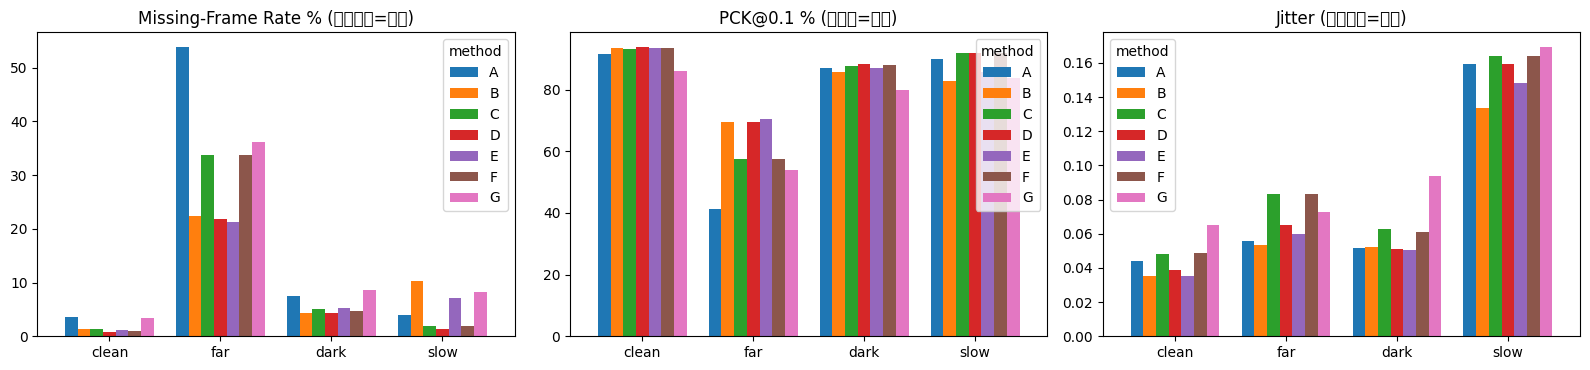

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, title in zip(ax, ["MFR", "PCK", "jitter"], ["Missing-Frame Rate % (น้อย=ดี)", "PCK@0.1 % (มาก=ดี)", "Jitter (น้อย=ดี)"]):
    P = TABLE.pivot(index="condition", columns="method", values=col).loc[CONDITIONS]
    P.plot.bar(ax=a, rot=0, width=0.8); a.set_title(title); a.set_xlabel("")
plt.tight_layout(); plt.show()

## 6. Recognition — Sign Model (v10) ได้คำถูกไหม? (ตัวชี้วัดที่สำคัญที่สุด)
ใช้ `SignPipeline` จริง (`use_llm=False`) ป้อน landmark จากแต่ละวิธีเข้าไป → ดู **WER** (คำที่ accepted เทียบกับ label) และ **exact** (ถูกทั้งหมด). `+P` = อุดช่องว่าง ≤6 เฟรม + One-Euro.

In [15]:
def _rjob(f, ref, conds, methods):
    sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
    return recog_clip(f, ref, MODEL_DIR, conds, methods)

t0 = time.time()
RECOG = Parallel(n_jobs=N_JOBS)(delayed(_rjob)(f, r, ("clean", "far"), METH) for f, r in ITEMS)
print(f"{time.time() - t0:.0f} s")
rows = []
for (f, ref), r in zip(ITEMS, RECOG):
    for (c, m, p), (w, h) in r.items():
        rows.append(dict(clip=Path(f).stem, cond=c, method=m + ("+P" if p else ""), wer=w, exact=float(w == 0)))
RDF = pd.DataFrame(rows)
REC = RDF.groupby(["cond", "method"])[["wer", "exact"]].mean().round(3).unstack(0)
REC

774 s


wer         exact       
cond    clean    far  clean    far
method                            
A       0.585  0.844  0.286  0.071
A+P     0.656  0.862  0.214  0.071
B       0.666  0.908  0.214  0.000
B+P     0.656  0.908  0.214  0.000
C       0.585  0.818  0.286  0.071
C+P     0.585  0.864  0.286  0.071
D       0.595  0.936  0.286  0.000
D+P     0.513  0.954  0.357  0.000
E       0.523  0.954  0.357  0.000
E+P     0.513  0.943  0.357  0.000
F       0.585  0.818  0.286  0.071
F+P     0.585  0.864  0.286  0.071
G       0.595  0.882  0.286  0.071
G+P     0.599  0.882  0.286  0.071

## 7. ดูด้วยตา: เฟรมที่ baseline พลาด แต่วิธีเราเจอ
(เพราะ PCK/MFR อิง reference ที่เราสร้างเอง — ภาพนี้ให้ตรวจว่ามือที่ "กู้ได้" เป็นมือจริง และ landmark อยู่ตำแหน่งถูก)

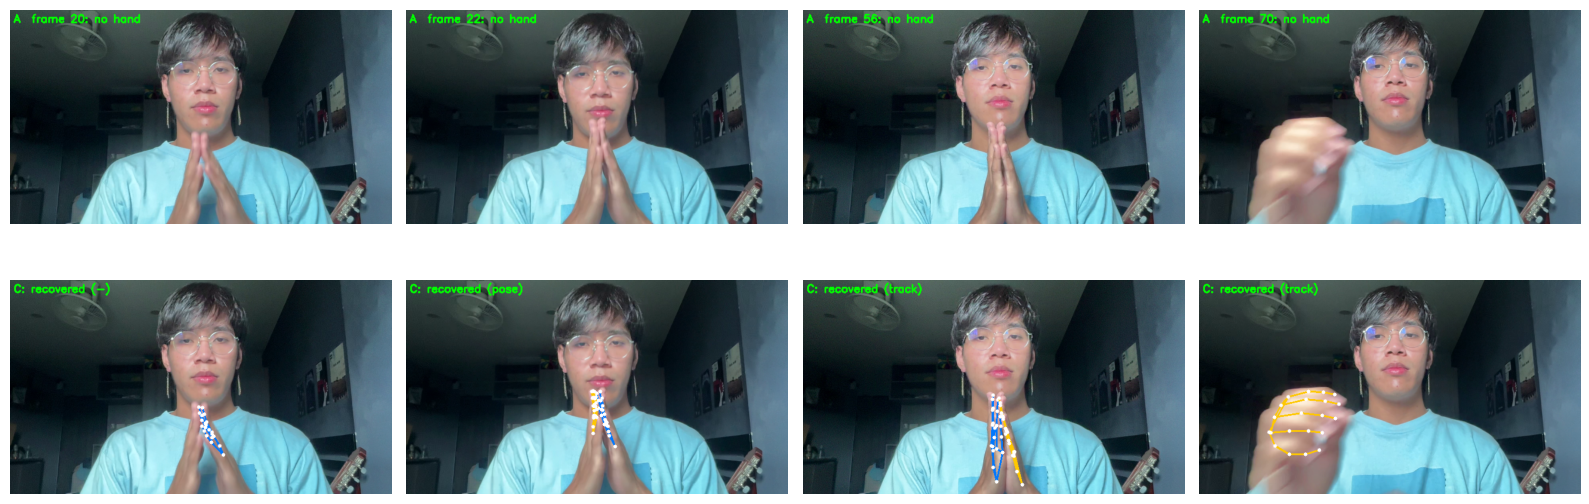

A found a hand in 49% of frames, C in 58%; 8 frames recovered


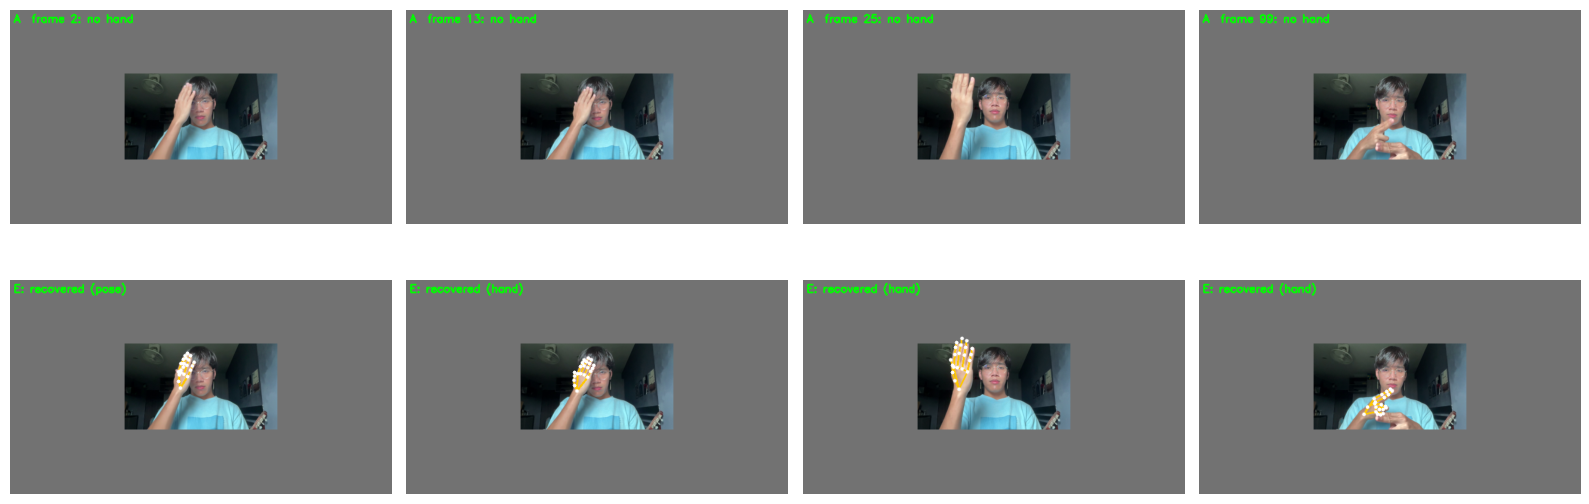

A found a hand in 7% of frames, E in 34%; 33 frames recovered


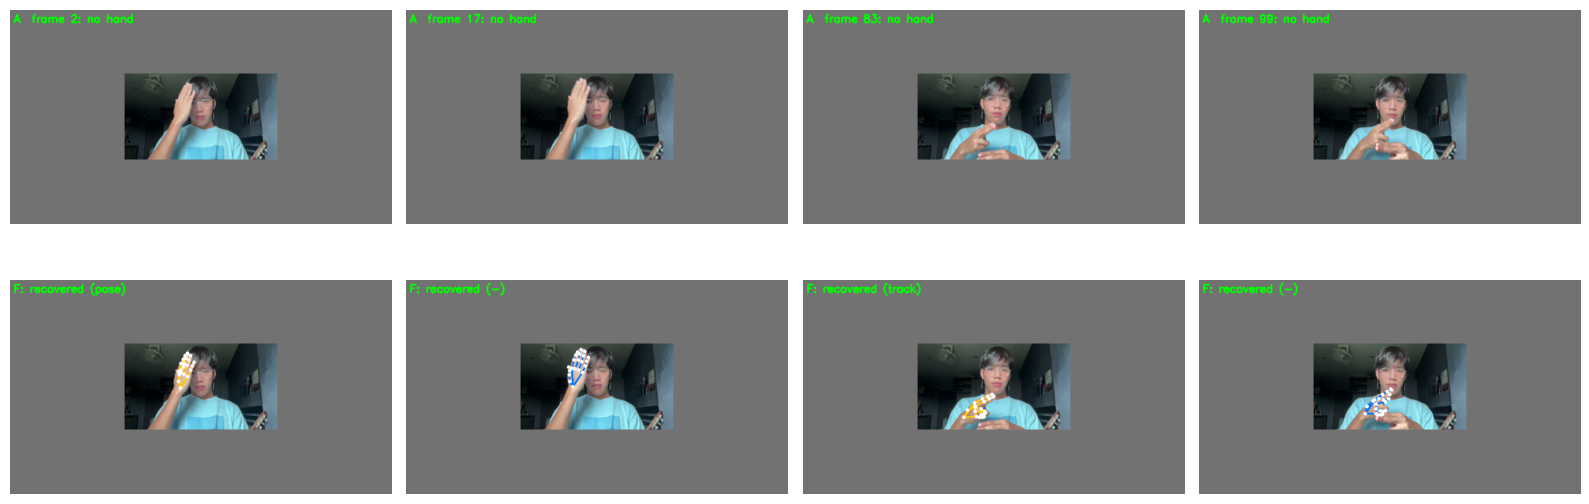

A found a hand in 7% of frames, F in 50%; 43 frames recovered


In [14]:
CONN = [(0,1),(1,2),(2,3),(3,4),(0,5),(5,6),(6,7),(7,8),(5,9),(9,10),(10,11),(11,12),(9,13),(13,14),(14,15),(15,16),(13,17),(17,18),(18,19),(19,20),(0,17)]

def draw(rgb, lh, rh, label=""):
    im = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR).copy(); H, W = im.shape[:2]
    for hand, col in ((lh, (255, 120, 0)), (rh, (0, 200, 255))):
        if not hand.any():
            continue
        p = (hand[:, :2] * [W, H]).astype(int)
        for a, b in CONN:
            cv2.line(im, tuple(p[a]), tuple(p[b]), col, 2)
        for q in p:
            cv2.circle(im, tuple(q), 3, (255, 255, 255), -1)
    cv2.putText(im, label, (6, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def gallery(clip, cond="clean", method="E", n=4, max_frames=100):
    frames, ts = load_clip(clip, max_frames)
    fr = [degrade(f, cond)[0] for f in frames]
    a = run_method(A_Holistic, fr, ts); b = run_method(METHODS[method], fr, ts)
    ha = np.array([x.any() for x in a["rh"]] ); hb = np.array([x.any() for x in b["rh"]])
    ha |= np.array([x.any() for x in a["lh"]]); hb |= np.array([x.any() for x in b["lh"]])
    cand = np.where(~ha & hb)[0]
    pick = cand[np.linspace(0, len(cand) - 1, min(n, len(cand))).astype(int)] if len(cand) else []
    fig, ax = plt.subplots(2, max(len(pick), 1), figsize=(4 * max(len(pick), 1), 6.2), squeeze=False)
    for j, i in enumerate(pick):
        ax[0, j].imshow(draw(fr[i], a["lh"][i], a["rh"][i], f"A  frame {i}: no hand")); ax[1, j].imshow(draw(fr[i], b["lh"][i], b["rh"][i], f"{method}: recovered ({b['src']['R'][i]})"))
        ax[0, j].axis("off"); ax[1, j].axis("off")
    plt.tight_layout(); plt.show()
    print(f"A found a hand in {ha.mean():.0%} of frames, {method} in {hb.mean():.0%}; {len(cand)} frames recovered")

gallery(ITEMS[0][0], "clean", "C")      # สวัสดี (IMG_3293)
gallery(ITEMS[9][0], "far", "E")        # ประโยค ผู้เซ็นไกล
if HAS_YOLO:
    gallery(ITEMS[9][0], "far", "F")        # เหมือนกัน แต่ ROI จาก YOLO

## 8. Post-process: เลือก One-Euro ให้นิ่งโดยไม่หน่วง
`distortion` = ระยะเฉลี่ยของ landmark หลังกรองเทียบกับก่อนกรอง (หน่วยขนาดมือ) — ยิ่งมากแปลว่าหน่วง/ผิดรูปมาก. เลือกจุดที่ jitter ลดแต่ distortion ต่ำ

In [16]:
frames, ts = load_clip(ITEMS[9][0], 100)
R0 = run_method(C_Recovery, frames, ts); hw0 = frames[0].shape[:2]
rows = [dict(min_cutoff=0, beta=0, jitter=jitter(R0, hw0), distortion=0.0)]
for mc in (0.5, 1.0, 2.0, 4.0):
    for beta in (0.0, 4.0, 8.0, 20.0):
        R1 = dict(R0)
        for k in ("lh", "rh"):
            R1[k] = smooth_sequence(R0[k], R0["t"], mc, beta, hw0)
        d = []
        for k in ("lh", "rh"):
            ok = np.array([x.any() for x in R0[k]])
            for i in np.where(ok)[0]:
                d.append(np.linalg.norm(px(R1[k][i], hw0) - px(R0[k][i], hw0), axis=1).mean() / max(hand_size(px(R0[k][i], hw0)), 1))
        rows.append(dict(min_cutoff=mc, beta=beta, jitter=jitter(R1, hw0), distortion=float(np.mean(d))))
SWEEP = pd.DataFrame(rows).round(4)
SWEEP

,min_cutoff,beta,jitter,distortion
0,0.0,0.0,0.0530,0.0000
1,0.5,0.0,0.0194,0.5986
2,0.5,4.0,0.0386,0.0512
3,0.5,8.0,0.0421,0.0336
4,0.5,20.0,0.0464,0.0184
5,1.0,0.0,0.0210,0.3714
6,1.0,4.0,0.0382,0.0485
7,1.0,8.0,0.0418,0.0322
8,1.0,20.0,0.0462,0.0178
9,2.0,0.0,0.0243,0.2077


## 9. สรุปผล + คำแนะนำ

### ผลที่วัดได้ (iPhone 14 คลิป · CPU เครื่องนี้ · ทีละ process สำหรับความเร็ว)

**ความเร็ว (ms/เฟรม, fps)**: A Holistic **34 (29)** · C Holistic+ROI **57 (17.6)** · F **68 (14.8)** · B **78 (12.8)** · D/E **94 (10.6)** · G **124 (8.1)**

**Missing-Frame Rate % (น้อย=ดี) / PCK@0.1 %**

| เงื่อนไข | A baseline | B hand | **C ROI-recovery** | D fusion | E | F (YOLO-ROI) | G (YOLO-first) |
|---|---|---|---|---|---|---|---|
| clean | 3.5 / 91.6 | 1.3 / 93.5 | **1.3 / 93.2** | 0.8 / 93.8 | 1.2 / 93.5 | 1.1 / 93.5 | 3.4 / 86.1 |
| far (มือเล็ก) | 53.9 / 41.4 | 22.4 / 69.6 | 33.8 / 57.4 | 21.9 / 69.5 | **21.3 / 70.4** | 33.8 / 57.4 | 36.1 / 54.1 |
| dark | 7.5 / 86.9 | 4.3 / 85.8 | 5.1 / 87.6 | **4.3 / 88.1** | 5.3 / 87.1 | 4.7 / 87.8 | 8.6 / 79.8 |
| slow (fps÷3) | 4.0 / 90.0 | **10.3 / 82.9 (แย่ลง)** | **1.8 / 91.9** | 1.3 / 91.8 | 7.1 / 85.5 | 1.8 / 91.9 | 8.2 / 83.6 |

### อ่านผลอย่างตรงไปตรงมา
1. **ปัญหา "มือจับไม่โดน" แก้ได้จริง และต้นเหตุคือ Holistic ตามมือด้วย pose-ROI**: เมื่อมือเล็ก/ไกล Holistic พลาด **54%** → วิธีที่ใช้ Hand Landmarker/ROI เหลือ **~21–22%** (PCK 41→70). ยืนยันข้อสรุปข้อ 5 ของคุณ
2. **ไม่ควรเปลี่ยนไปใช้ Hand Landmarker เต็มเฟรมอย่างเดียว (B/E)**: ตอนเบราว์เซอร์ส่งเฟรมช้า (`slow`) tracker ของมันหลุดมากกว่า Holistic (10.3% vs 4.0%). วิธีที่ **Holistic ยังเป็นหลัก + ROI กู้เฉพาะเฟรมที่หาย (C)** ดีขึ้นทุกเงื่อนไข (slow 4.0→1.8, clean 3.5→1.3) ไม่เคยแย่กว่า A
3. **C คือจุดคุ้มสุดสำหรับ real-time**: +23 ms/เฟรมบน CPU (เสีย ~12 fps) แลกกับ MFR ลด ~2–3 เท่าในเงื่อนไขปกติ/เฟรมหล่น และยังไม่แตะ path เดิม (ตัด recovery ออกได้ทันที). มี cool-down (ลองใหม่ทุก 3 เฟรมเมื่อล้มเหลว) และ gate "ข้อมือยกอยู่" เพื่อไม่เสียเวลากับมือที่ไม่มี
4. **มือเล็ก/ไกลต้องใช้ full-frame Hand Landmarker (D/E) ร่วมด้วย** แต่แพงกว่า 94 ms → แนะนำ **โหมดปรับอัตโนมัติ**: ปกติใช้ C; เมื่ออัตรามือหาย (ขณะข้อมือยก) ใน ~1 วินาทีล่าสุดสูงเกินเกณฑ์ ให้สลับเป็น D/E ชั่วคราว (หรือเตือนผู้ใช้ให้เข้าใกล้กล้อง)
5. **YOLO (ตัวที่เทรนในแล็บนี้) ยังไม่ช่วย**: F ≡ C ในเงื่อนไข far เพราะ YOLO หา **0 กล่อง** (มือสูง ~12 px ที่ input 320; เทรนเบา 5 epoch/25% ของ data บน CPU, dataset เป็นมือใกล้กล้องเป็นหลัก) และใน clean เจอ 0.6 กล่อง/เฟรม. G (YOLO-first) แย่กว่าและช้าที่สุด. **ไม่ได้แปลว่า YOLO ไร้ประโยชน์** — แปลว่าโมเดลนี้เบาเกินไป/ข้อมูลไม่ตรงโดเมน. ทิศทางต่อ: เทรนที่ ≥640 px พร้อม augmentation ซูมออก และ pseudo-label ด้วย reference ของแล็บนี้ จากคลิปของเราเอง (ต้องเทรนบน GPU)
6. **Post-process (One-Euro + อุดช่องว่าง)** ลด jitter ระดับ landmark ได้ ~21% ที่ `min_cutoff=1, beta=8` (distortion 3%) แต่ **ไม่ทำให้ recognition ดีขึ้น** (A+P clean WER 0.656 vs 0.585; D+P ดีขึ้น 0.595→0.513 — สลับไปมา อยู่ในระดับ noise ของ 14 คลิป) → ใช้กับการแสดงผล/UX ได้ แต่ **ยังไม่ควรป้อนเข้า Sign Model** จนกว่าจะวัดบนชุดใหญ่ขึ้น
7. **Recognition (WER ของ Sign Model v10)**: clean A 0.585 · C 0.585 · D 0.595 · E 0.523 · D+P 0.513 — **ต่างกันไม่เกินระดับ noise** (n=14); far ทุกวิธี ≥ 0.82 (C/F ดีสุด 0.818) เพราะที่ระยะไกล ทั้งตัวคนเล็กลง Sign Model เองก็พัง ไม่ใช่แค่มือ. ดังนั้น **การจับมือได้มากขึ้นยังไม่ถูกพิสูจน์ว่าให้คำถูกขึ้น** — ต้องชุดทดสอบใหญ่กว่านี้ และอาจต้องเทรน Sign Model ด้วยมือที่ถูกกู้ (`masked_hand.py`)
8. **Normalization**: ตัวที่ป้อน Uni-Sign (ข้อมือ + สเกลลำตัว) ไม่ invariant ต่อมือยื่นเข้ากล้อง (drift 0.52) และการหมุน (0.09); `zoom` แก้แรก (0.00), `zoom+rotation` แก้ทั้งคู่ (0.00). ใช้ได้ทันทีกับ hand-shape/fingerspelling; **ห้ามเปลี่ยนอินพุต Uni-Sign โดยไม่เทรนใหม่**

### ข้อจำกัด (อ่านก่อนเชื่อตัวเลข)
* ไม่มี ground-truth landmark ที่คนติดป้าย: PCK/MFR วัดเทียบ **reference แบบ consensus** (ลำเอียงเข้าหาวิธีที่ใช้ Hand Landmarker) · false positive ของวิธี ROI สูงขึ้นที่ far (7–9% vs 3%)
* เงื่อนไข far/dark/slow เป็น **การจำลอง** บนคลิปเดิม ไม่ใช่เซสชันเบราว์เซอร์จริง → ใช้ cell Live (หัวข้อ 10) ทดสอบกล้องจริงเทียบ A กับ C/D แบบแบ่งจอ
* WER สัมบูรณ์แย่กว่ารายงานเดิมของ production เพราะแล็บนี้จำกัดภาพ 640 px, ≤260 เฟรม, นับเฉพาะคำ `accepted` → **เทียบกันเองเท่านั้น**
* ms วัดบน CPU; เบราว์เซอร์ (GPU/WASM-SIMD) ต่างออกไป แต่ **สัดส่วน** ระหว่างวิธีน่าใกล้เคียง

### ขั้นต่อไปที่แนะนำ
1. ทดสอบกล้องจริง (cell Live) เทียบ A vs C vs D ในท่าที่เคยหลุด → ตัดสินใจว่า C พอไหม
2. พอร์ต C ไปเบราว์เซอร์: `HandLandmarker` (tasks-vision ใช้ `.task` ตัวเดียวกัน) ในโหมด IMAGE บน canvas crop 256 px + ROI จาก pose/ตำแหน่งเดิม + cool-down 2 เฟรม (ตรรกะอยู่ใน `C_Recovery.rescue`, ~60 บรรทัด)
3. สวิตช์ C ⇄ D อัตโนมัติจากอัตรามือหาย
4. YOLO รอบสอง (GPU, ≥640 px, ซูมออก, pseudo-label จากคลิปเรา) แล้วรัน F/G ซ้ำ · ตรวจ license AGPL-3.0 ก่อนใช้งานจริง
5. ชุดทดสอบ recognition ที่ใหญ่ขึ้น (≥50 คลิป) ก่อนสรุปเรื่อง accuracy ปลายทาง

## 10. Live — เปิดกล้องทดสอบ (รัน cell ด้านล่างแล้วกล้องเปิดทันที · ตัวแปร `OPEN_CAMERA` บนสุดของ cell)
เลือกวิธีด้วยตัวแปร `METHOD` บนสุดของ cell (ค่าเริ่มต้น `"C"`) · คีย์: **s** = แบ่งจอ เทียบ A (ซ้าย) กับ `METHOD` (ขวา) · **p** = เปิด/ปิด post-process (One-Euro) · **q** = ออก
HUD: ms/เฟรม, fps, แหล่งที่มาของมือแต่ละข้าง (`holistic/hand/track/pose/-`), และ **อัตรามือหาย 100 เฟรมล่าสุด** (เฉพาะตอนข้อมือยกอยู่) — ลองยกมือไกลกล้อง, หมุนข้อมือ, สะบัดเร็ว, เปลี่ยนมุม แล้วดูว่าวิธีไหนไม่หลุด

In [17]:
METHOD = "C"      # วิธีที่ใช้: A Holistic · B hand · C Holistic+ROI recovery (แนะนำ) · D fusion · E hand+ROI · F/G YOLO
SMOOTH = False    # True = One-Euro กรอง landmark (เฉพาะการแสดงผล)

class Live:
    def __init__(self, key):
        self.key, self.ex = key, METHODS[key]()
        self.filt = {"lh": HandSmoother(1.0, 8.0), "rh": HandSmoother(1.0, 8.0)}
        self.miss = []

    def step(self, rgb, t_ms, smooth):
        pose, lh, rh, face, bs = self.ex.frame(rgb, t_ms)
        hw = rgb.shape[:2]
        out = {}
        for k, h in (("lh", lh), ("rh", rh)):
            if smooth and h.any():
                h = self.filt[k](h, t_ms / 1000.0, hw)
            elif not h.any():
                self.filt[k].reset()
            out[k] = h
        up = [(pose[15, 3] > .5 and pose[15, 1] < pose[23, 1]), (pose[16, 3] > .5 and pose[16, 1] < pose[24, 1])]
        for u, k in zip(up, ("lh", "rh")):
            if u:
                self.miss.append(0 if out[k].any() else 1)
        self.miss = self.miss[-100:]
        return out["lh"], out["rh"]

    def hud(self, im):
        ms = np.mean(self.ex.ms[-30:]) if self.ex.ms else 0
        mr = 100 * np.mean(self.miss) if self.miss else 0
        s = f"{self.ex.name} | {ms:.0f} ms ({1000 / max(ms, 1):.0f} fps) | L:{self.ex.src['L'][-1] if self.ex.src['L'] else '-'} R:{self.ex.src['R'][-1] if self.ex.src['R'] else '-'} | miss {mr:.0f}%"
        cv2.putText(im, s, (6, im.shape[0] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        return im

def live(source=SOURCE, start=METHOD):
    cap = cv2.VideoCapture(source)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640); cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
    cur, base, split, smooth, t0 = Live(start), None, False, SMOOTH, time.perf_counter()
    try:
        while True:
            ok, bgr = cap.read()
            if not ok:
                break
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB); t = (time.perf_counter() - t0) * 1000
            lh, rh = cur.step(rgb, t, smooth)
            right = cur.hud(cv2.cvtColor(draw(rgb, lh, rh), cv2.COLOR_RGB2BGR))
            if split:
                base = base or Live("A")
                a, b = base.step(rgb, t, smooth)
                left = base.hud(cv2.cvtColor(draw(rgb, a, b), cv2.COLOR_RGB2BGR))
                right = np.concatenate([left, right], 1)
            cv2.imshow("lab4 hand extractor", right)
            k = cv2.waitKey(1) & 0xFF
            if k == ord("q"):
                break
            if k == ord("s"):
                split = not split
            if k == ord("p"):
                smooth = not smooth
    finally:
        cap.release(); cv2.destroyAllWindows(); cur.ex.close()
        if base:
            base.ex.close()

# รัน cell นี้ = เปิดกล้องทันที (กด q ในหน้าต่างกล้องเพื่อหยุด) · Run All จะเปิดกล้องด้วย → ตั้ง OPEN_CAMERA = False ถ้าไม่ต้องการ
OPEN_CAMERA = True
if OPEN_CAMERA:
    assert METHOD in METH, f"METHOD={METHOD!r} ใช้ไม่ได้ (มี {METH})"
    live()

KeyboardInterrupt: 